# First try a entrenar la ResNet amb la training data de DENTEX

In [1]:
from pathlib import Path
import json

import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models

import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image

## Inserint validació i entrenament (json e img)

In [2]:
data_dir = Path("data/raw/dentex")

val_images_dir = (
    data_dir
    / "validation_data"
    / "quadrant_enumeration_disease"
    / "xrays"
)

train_images_dir = (
    data_dir / "training_data" / "quadrant-enumeration-disease" / "xrays"

)

VAL_json_path = data_dir / "validation_triple.json"
train_json_path = data_dir / "training_data" / "quadrant-enumeration-disease" / "train_quadrant_enumeration_disease.json"


with open(VAL_json_path, "r") as f:
    VAL_data = json.load(f)

with open(train_json_path, "r") as f:
    train_data = json.load(f)


print(f"Imatges: {len(VAL_data['images'])}")
print(f"Anotacions: {len(VAL_data['annotations'])}")
print(VAL_data.keys())

print(f"Imatges: {len(train_data['images'])}")
print(f"Anotacions: {len(train_data['annotations'])}")
print(train_data.keys())

#definim les patologies en diccionaris (en aquest cas de validació)

quadrants = {x["id"]: x["name"] for x in VAL_data["categories_1"]}
teeth = {x["id"]: x["name"] for x in VAL_data["categories_2"]}
diagnoses = {x["id"]: x["name"] for x in VAL_data["categories_3"]}



Imatges: 50
Anotacions: 182
dict_keys(['images', 'annotations', 'categories_1', 'categories_2', 'categories_3'])
Imatges: 705
Anotacions: 3529
dict_keys(['images', 'annotations', 'categories_1', 'categories_2', 'categories_3'])


## Fem els dataframes per val i per train

In [3]:
import pandas as pd

# Fila per cada imatge
labels_df = pd.DataFrame(train_data["images"])[["id", "file_name","height", "width"]]
#canviarem el nom de id, per image_id, per a que sigui més clar
labels_df.rename(columns = {"id": "image_id"}, inplace = True)

print(labels_df.head())# Ara definim les etiquetes de les patologies

label_names = {
    0: "has_impacted",
    1: "has_caries",
    2: "has_periapical_lesion",
    3: "has_deep_caries"
}

for label in label_names.values():
    labels_df[label] = 0


#i ara hem d'omplir les etiquetes cada cop que tenim el diagnostic corresponent
# només m'interessa la categoria 3, que és la que ens diu quina patologia és

for ann in train_data["annotations"]:
    image_id = ann["image_id"]
    diagnosis_id = ann["category_id_3"]
    label_name = label_names[diagnosis_id]
    labels_df.loc[labels_df["image_id"] == image_id, label_name] = 1

# i ara per validation


labels_val_df = pd.DataFrame(VAL_data["images"])[["id", "file_name","height", "width"]]
#canviarem el nom de id, per image_id, per a que sigui més clar
labels_val_df.rename(columns = {"id": "image_id"}, inplace = True)

print(labels_val_df.head())# Ara definim les etiquetes de les patologies

for label in label_names.values():
    labels_val_df[label] = 0


#i ara hem d'omplir les etiquetes cada cop que tenim el diagnostic corresponent
# només m'interessa la categoria 3, que és la que ens diu quina patologia és

for ann in VAL_data["annotations"]:
    image_id = ann["image_id"]
    diagnosis_id = ann["category_id_3"]
    label_name = label_names[diagnosis_id]
    labels_val_df.loc[labels_val_df["image_id"] == image_id, label_name] = 1

labels_val_df.head(10)
labels_df.head(10)

   image_id      file_name  height  width
0         1  train_673.png    1316   2744
1         2  train_283.png    1504   2872
2         3  train_435.png    1316   2909
3         4   train_95.png    1504   2872
4         5  train_475.png    1504   2872
   image_id   file_name  height  width
0         1  val_15.png    1316   2892
1         2  val_38.png    1316   2942
2         3  val_33.png    1316   2987
3         4  val_30.png    1504   2872
4         5   val_5.png    1316   2970


,image_id,file_name,height,width,has_impacted,has_caries,has_periapical_lesion,has_deep_caries
0,1,train_673.png,1316,2744,1,1,1,0
1,2,train_283.png,1504,2872,1,1,0,0
2,3,train_435.png,1316,2909,0,0,0,0
3,4,train_95.png,1504,2872,0,1,1,1
4,5,train_475.png,1504,2872,0,0,1,1
5,6,train_62.png,1316,2867,0,1,0,1
6,7,train_637.png,1536,3076,0,1,0,1
7,8,train_187.png,1316,2815,1,1,1,1
8,9,train_509.png,1316,2928,1,1,1,1
9,10,train_31.png,1504,2872,0,1,0,0


### Comprobem si les dades estan totes bé. 

In [4]:
diagnosis_columns = [
    "has_impacted",
    "has_caries",
    "has_periapical_lesion",
    "has_deep_caries",
]

print("TRAIN")
print("Nombre d'imatges:", len(labels_df))
display(labels_df[diagnosis_columns].sum())

print("\nVALIDATION")
print("Nombre d'imatges:", len(labels_val_df))
display(labels_val_df[diagnosis_columns].sum())

TRAIN
Nombre d'imatges: 705


has_impacted             254
has_caries               623
has_periapical_lesion    116
has_deep_caries          321
dtype: int64


VALIDATION
Nombre d'imatges: 50


has_impacted             16
has_caries               37
has_periapical_lesion     7
has_deep_caries          20
dtype: int64

### Has_impacted test

In [5]:
print("TRAIN — dents impactades")
display(labels_df["has_impacted"].value_counts())

print("VALIDATION — dents impactades")
display(labels_val_df["has_impacted"].value_counts())

TRAIN — dents impactades


has_impacted
0    451
1    254
Name: count, dtype: int64

VALIDATION — dents impactades


has_impacted
0    34
1    16
Name: count, dtype: int64

In [6]:
assert set(labels_df["has_impacted"].unique()) <= {0, 1}
assert set(labels_val_df["has_impacted"].unique()) <= {0, 1}
assert labels_df["has_impacted"].isna().sum() == 0
assert labels_val_df["has_impacted"].isna().sum() == 0


print(train_images_dir / labels_df.iloc[0]["file_name"])
print(val_images_dir / labels_val_df.iloc[0]["file_name"])

data\raw\dentex\training_data\quadrant-enumeration-disease\xrays\train_673.png
data\raw\dentex\validation_data\quadrant_enumeration_disease\xrays\val_15.png


data\raw\dentex\training_data\quadrant-enumeration-disease\xrays\train_673.png


data\raw\dentex\validation_data\quadrant_enumeration_disease\xrays\val_15.png

# Comencem a entrenar les imatges i a fer el model 

In [7]:
class OPGDataset(Dataset):
    def __init__(self, labels_df, images_dir, transform=None):
        self.labels_df = labels_df.reset_index(drop=True)
        self.images_dir = Path(images_dir)
        self.transform = transform

    def __len__(self):
        return len(self.labels_df)

    def __getitem__(self, index):
        row = self.labels_df.iloc[index]

        # Carrega l'orto i la passa a RGB:
        # visualment continuarà sent grisa, però tindrà 3 canals,
        # que és el format que espera la ResNet preentrenada.
        image_path = self.images_dir / row["file_name"]
        image = Image.open(image_path).convert("RGB")

        if self.transform:
            image = self.transform(image)

        # Etiqueta binària: 0 = no impactada, 1 = impactada
        target = torch.tensor(row["has_impacted"], dtype=torch.long)

        return image, target

Les transformacions per a normalitzar les imatges

In [8]:
train_transform = transforms.Compose([
    transforms.Resize((256, 512)),
    transforms.RandomAffine(
        degrees=3,
        translate=(0.02, 0.02),
        scale=(0.95, 1.05)
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

val_transform = transforms.Compose([
    transforms.Resize((256, 512)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

## Ara la capa final del model

In [9]:
import random
import numpy as np
import torch
import torch.nn as nn
from torchvision import models

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False


device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

baseline_checkpoint_path = (
    "models/resnet18_impacted_weighted_feature_ext.pt"
)

finetune_checkpoint_path = (
    "models/resnet18_impacted_layer4_finetune.pt"
)

## Ara ja cridem a les funcions que toquen 

In [10]:
from torch.utils.data import DataLoader

train_dataset = OPGDataset(
    labels_df,
    train_images_dir,
    transform=train_transform
)

val_dataset = OPGDataset(
    labels_val_df,
    val_images_dir,
    transform=val_transform
)

batch_size = 8

#ara amb el dataloader li tirem els datasets
#només shuflejem el train

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,      # canvia l'ordre a cada època
    num_workers=0      # opció segura per Windows + notebook
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False,     # validació sempre en ordre estable
    num_workers=0
)

# Comparació Grad-CAM: feature extraction vs fine-tuning

Aquest notebook no torna a entrenar els models. Carrega els dos checkpoints existents i compara on mira cadascun.

- `baseline_model`: només s'havia entrenat la capa `fc`.
- `finetuned_model`: s'havien entrenat `layer4` i `fc`.

Executa les cel·les anteriors de preparació de dades i després continua des d'aquí.

In [11]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    roc_auc_score,
    average_precision_score
)
from collections import defaultdict
import torch.nn.functional as F


def load_resnet18_checkpoint(checkpoint_path):
    model = models.resnet18(weights=None)
    model.fc = nn.Linear(model.fc.in_features, 2)

    model.load_state_dict(
        torch.load(
            checkpoint_path,
            map_location=device,
            weights_only=True
        )
    )

    # No entrenarem: només inferència i Grad-CAM.
    for parameter in model.parameters():
        parameter.requires_grad = False

    return model.to(device).eval()


baseline_model = load_resnet18_checkpoint(
    baseline_checkpoint_path
)

finetuned_model = load_resnet18_checkpoint(
    finetune_checkpoint_path
)

print("Models carregats correctament.")

Models carregats correctament.


In [12]:
def evaluate_model(model):
    targets_list = []
    predictions_list = []
    probabilities_list = []

    model.eval()

    with torch.no_grad():
        for images, targets in val_loader:
            images = images.to(device)

            logits = model(images)
            probabilities = torch.softmax(logits, dim=1)[:, 1]
            predictions = logits.argmax(dim=1)

            targets_list.extend(targets.numpy())
            predictions_list.extend(predictions.cpu().numpy())
            probabilities_list.extend(probabilities.cpu().numpy())

    results = labels_val_df[
        ["image_id", "file_name", "has_impacted"]
    ].copy()

    results["prediction"] = predictions_list
    results["prob_impacted"] = probabilities_list

    return results


baseline_results = evaluate_model(baseline_model)
finetuned_results = evaluate_model(finetuned_model)


def classification_metrics(name, results):
    y_true = results["has_impacted"]
    y_pred = results["prediction"]
    y_prob = results["prob_impacted"]

    matrix = confusion_matrix(y_true, y_pred)

    return {
        "model": name,
        "accuracy": (y_true == y_pred).mean(),
        "recall_impacted": matrix[1, 1] / matrix[1].sum(),
        "roc_auc": roc_auc_score(y_true, y_prob),
        "average_precision": average_precision_score(y_true, y_prob)
    }


classification_comparison = pd.DataFrame([
    classification_metrics(
        "Feature extraction",
        baseline_results
    ),
    classification_metrics(
        "Fine-tuning",
        finetuned_results
    )
])

display(classification_comparison)

,model,accuracy,recall_impacted,roc_auc,average_precision
0,Feature extraction,0.66,0.4375,0.643382,0.456721
1,Fine-tuning,0.64,0.3750,0.696691,0.516448


In [13]:
# Preparem les bounding boxes reals d'impactació.
image_id_by_filename = {
    image_info["file_name"]: image_info["id"]
    for image_info in VAL_data["images"]
}

impacted_boxes_by_image_id = defaultdict(list)

for annotation in VAL_data["annotations"]:
    if annotation["category_id_3"] == 0:
        impacted_boxes_by_image_id[
            annotation["image_id"]
        ].append(annotation["bbox"])


def get_impacted_boxes(file_name):
    image_id = image_id_by_filename[file_name]
    return impacted_boxes_by_image_id.get(image_id, [])


print(
    "Imatges positives amb boxes:",
    len(impacted_boxes_by_image_id)
)

Imatges positives amb boxes: 16


In [14]:
class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.activations = None
        self.gradients = None

        self.forward_handle = target_layer.register_forward_hook(
            self._save_activations
        )

    def _save_activations(self, module, inputs, output):
        self.activations = output
        output.register_hook(self._save_gradients)

    def _save_gradients(self, gradients):
        self.gradients = gradients

    def generate(self, input_tensor, class_index=1):
        self.model.eval()
        self.model.zero_grad(set_to_none=True)

        # Les capes estan congelades, però necessitem el gradient
        # respecte de l'entrada per construir el Grad-CAM.
        input_tensor = input_tensor.clone().detach()
        input_tensor.requires_grad_(True)

        logits = self.model(input_tensor)
        probabilities = torch.softmax(logits, dim=1)

        prediction = logits.argmax(dim=1).item()
        probability_impacted = probabilities[0, 1].item()

        logits[0, class_index].backward()

        activations = self.activations.detach()
        gradients = self.gradients.detach()

        weights = gradients.mean(dim=(2, 3), keepdim=True)
        cam = (weights * activations).sum(dim=1)
        cam = torch.relu(cam).squeeze().cpu().numpy()

        cam_min = cam.min()
        cam_max = cam.max()

        if cam_max - cam_min > 1e-8:
            cam = (cam - cam_min) / (cam_max - cam_min)
        else:
            cam = np.zeros_like(cam)

        return cam, probability_impacted, prediction

    def remove_hook(self):
        self.forward_handle.remove()


baseline_gradcam = GradCAM(
    baseline_model,
    baseline_model.layer4[-1]
)

finetuned_gradcam = GradCAM(
    finetuned_model,
    finetuned_model.layer4[-1]
)

print("Grad-CAM preparat per als dos models.")

Grad-CAM preparat per als dos models.


In [15]:
def resize_cam_to_original_image(cam, pil_image):
    cam_tensor = torch.tensor(
        cam,
        dtype=torch.float32
    ).unsqueeze(0).unsqueeze(0)

    resized_cam = F.interpolate(
        cam_tensor,
        size=(pil_image.height, pil_image.width),
        mode="bilinear",
        align_corners=False
    )

    return resized_cam[0, 0].numpy()


def draw_boxes(axis, boxes, color="lime"):
    for x, y, width, height in boxes:
        axis.add_patch(
            Rectangle(
                (x, y),
                width,
                height,
                linewidth=2,
                edgecolor=color,
                facecolor="none"
            )
        )


def generate_cam_for_image(cam_engine, pil_image):
    input_tensor = val_transform(
        pil_image
    ).unsqueeze(0).to(device)

    cam, probability, prediction = cam_engine.generate(
        input_tensor,
        class_index=1
    )

    resized_cam = resize_cam_to_original_image(
        cam,
        pil_image
    )

    return resized_cam, probability, prediction


def compare_gradcams(file_name):
    pil_image = Image.open(
        val_images_dir / file_name
    ).convert("RGB")

    boxes = get_impacted_boxes(file_name)

    baseline_cam, baseline_prob, baseline_pred = (
        generate_cam_for_image(baseline_gradcam, pil_image)
    )

    finetuned_cam, finetuned_prob, finetuned_pred = (
        generate_cam_for_image(finetuned_gradcam, pil_image)
    )

    real_label = int(
        labels_val_df.loc[
            labels_val_df["file_name"] == file_name,
            "has_impacted"
        ].iloc[0]
    )

    figure, axes = plt.subplots(1, 3, figsize=(21, 5))

    axes[0].imshow(pil_image)
    draw_boxes(axes[0], boxes)
    axes[0].set_title(
        f"Original | real={real_label} | boxes={len(boxes)}"
    )

    axes[1].imshow(pil_image)
    axes[1].imshow(
        baseline_cam,
        cmap="jet",
        alpha=0.45,
        vmin=0,
        vmax=1
    )
    draw_boxes(axes[1], boxes)
    axes[1].set_title(
        f"Feature extraction\npred={baseline_pred} | "
        f"p={baseline_prob:.3f}"
    )

    axes[2].imshow(pil_image)
    axes[2].imshow(
        finetuned_cam,
        cmap="jet",
        alpha=0.45,
        vmin=0,
        vmax=1
    )
    draw_boxes(axes[2], boxes)
    axes[2].set_title(
        f"Fine-tuning\npred={finetuned_pred} | "
        f"p={finetuned_prob:.3f}"
    )

    for axis in axes:
        axis.axis("off")

    figure.suptitle(file_name, fontsize=14)
    plt.tight_layout()
    plt.show()

    return {
        "baseline_cam": baseline_cam,
        "finetuned_cam": finetuned_cam
    }

{'Vertader positiu': 'val_27.png', 'Fals negatiu': 'val_0.png', 'Fals positiu': 'val_4.png', 'Vertader negatiu': 'val_40.png'}

Vertader positiu: val_27.png


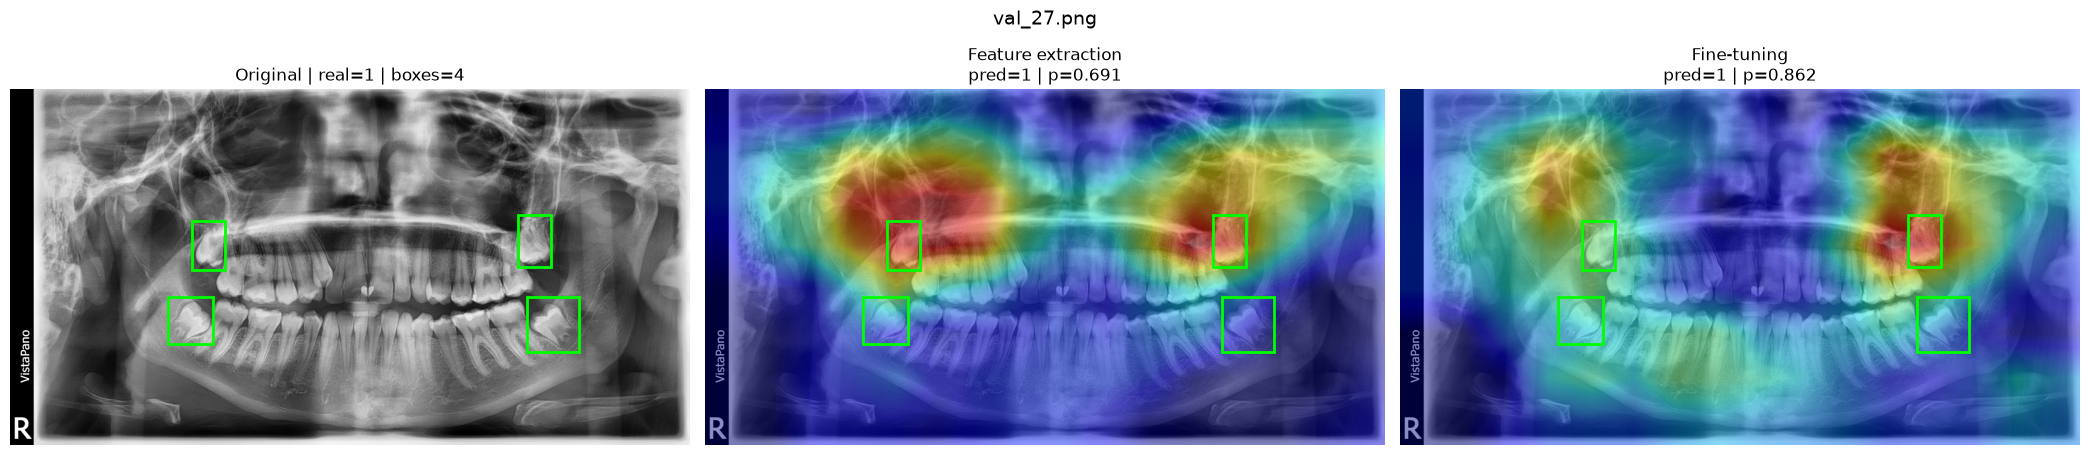


Fals negatiu: val_0.png


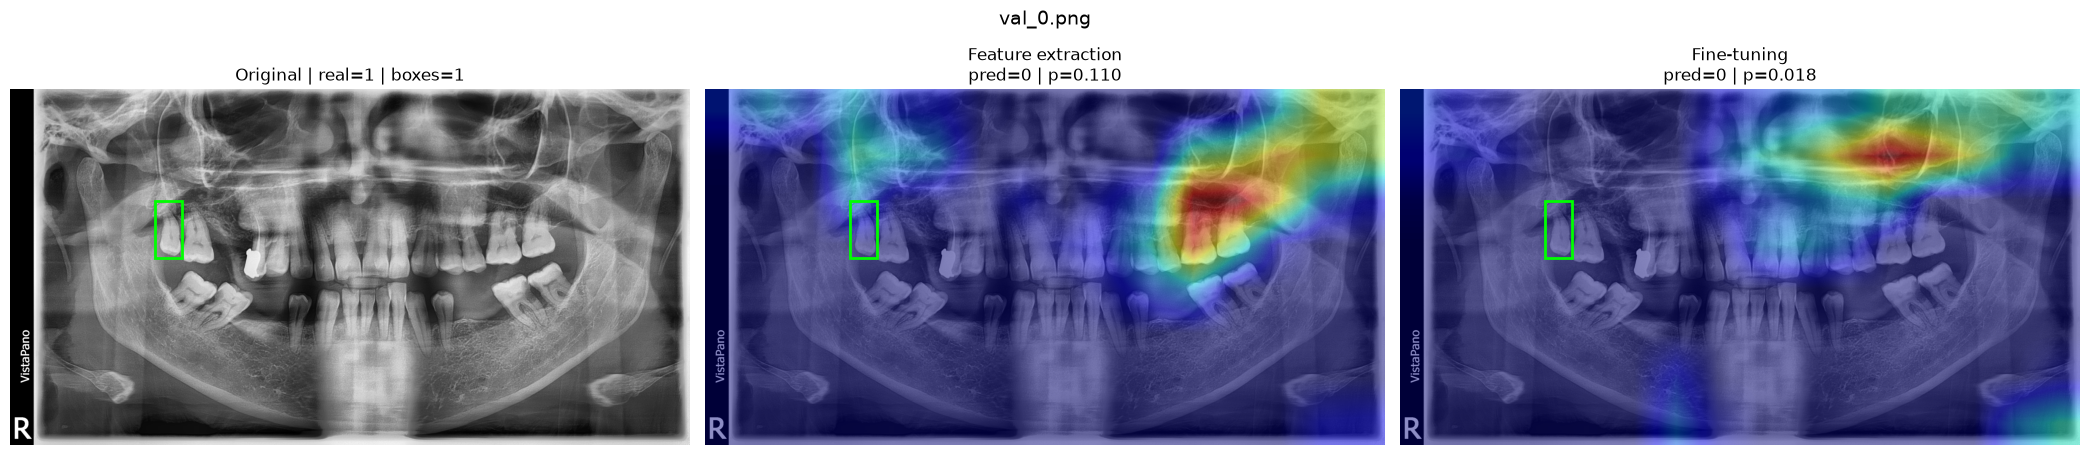


Fals positiu: val_4.png


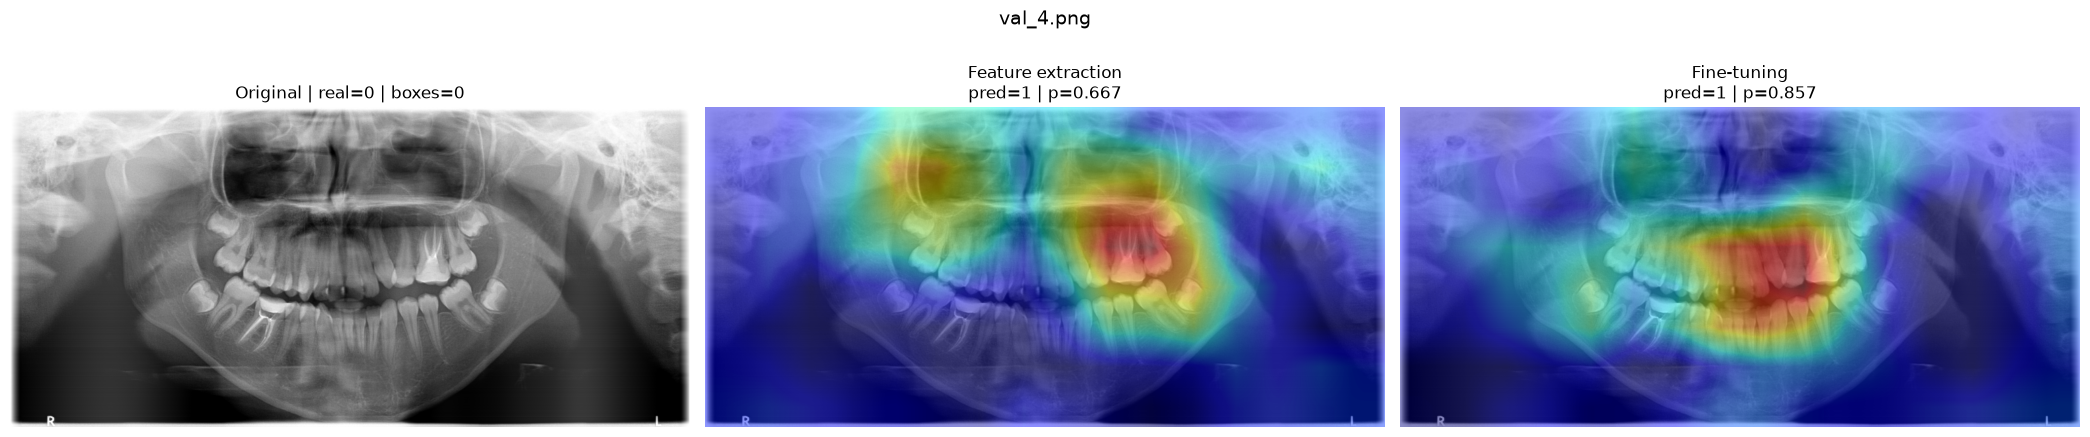


Vertader negatiu: val_40.png


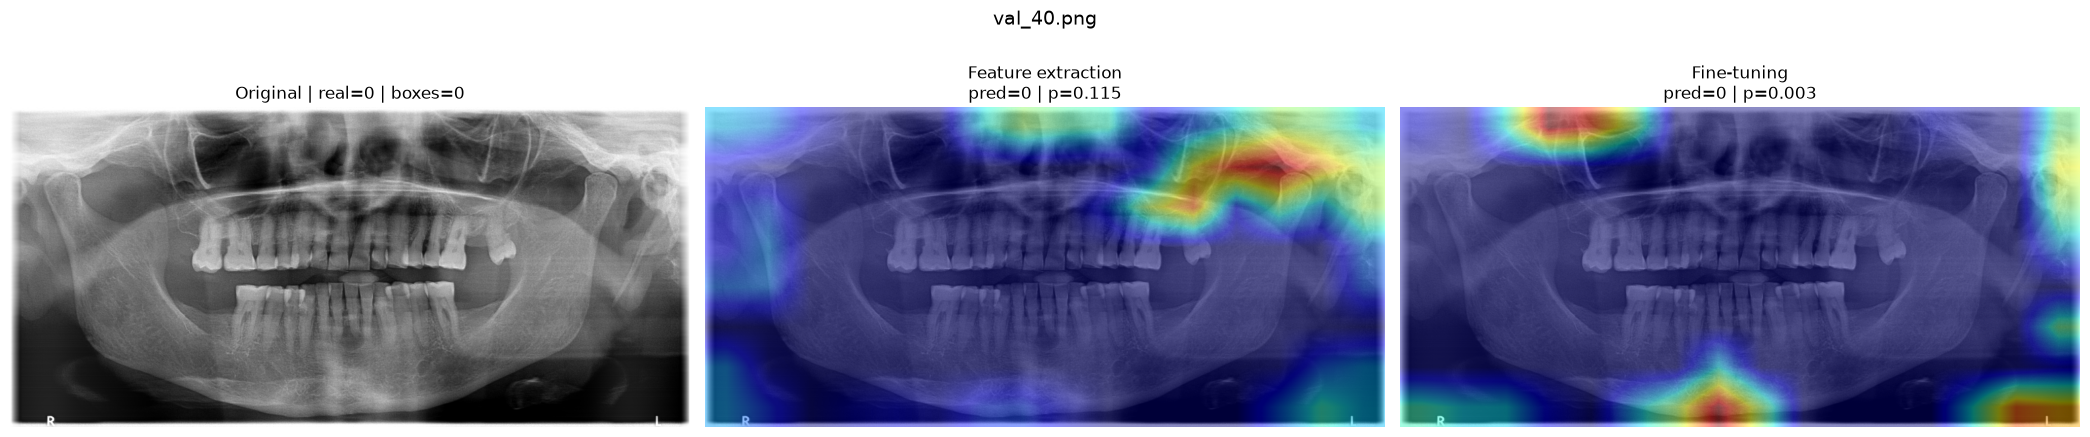

In [16]:
# Seleccionem exemples segons el resultat del model fine-tuned.
def add_result_type(results):
    results = results.copy()

    conditions = [
        (results["has_impacted"] == 1)
        & (results["prediction"] == 1),

        (results["has_impacted"] == 1)
        & (results["prediction"] == 0),

        (results["has_impacted"] == 0)
        & (results["prediction"] == 1)
    ]

    labels = [
        "Vertader positiu",
        "Fals negatiu",
        "Fals positiu"
    ]

    results["result_type"] = np.select(
        conditions,
        labels,
        default="Vertader negatiu"
    )

    return results


finetuned_results = add_result_type(finetuned_results)


def choose_example(result_type, ascending=False):
    subset = finetuned_results[
        finetuned_results["result_type"] == result_type
    ]

    if subset.empty:
        return None

    return (
        subset
        .sort_values("prob_impacted", ascending=ascending)
        .iloc[0]["file_name"]
    )


example_files = {
    "Vertader positiu": choose_example(
        "Vertader positiu",
        ascending=False
    ),
    "Fals negatiu": choose_example(
        "Fals negatiu",
        ascending=True
    ),
    "Fals positiu": choose_example(
        "Fals positiu",
        ascending=False
    ),
    "Vertader negatiu": choose_example(
        "Vertader negatiu",
        ascending=True
    )
}

print(example_files)

for result_type, file_name in example_files.items():
    if file_name is not None:
        print(f"\n{result_type}: {file_name}")
        compare_gradcams(file_name)

In [17]:
def boxes_to_mask(boxes, image_width, image_height):
    mask = np.zeros((image_height, image_width), dtype=bool)

    for x, y, width, height in boxes:
        x1 = max(0, int(np.floor(x)))
        y1 = max(0, int(np.floor(y)))
        x2 = min(image_width, int(np.ceil(x + width)))
        y2 = min(image_height, int(np.ceil(y + height)))

        mask[y1:y2, x1:x2] = True

    return mask


def calculate_localization_metrics(cam, boxes):
    image_height, image_width = cam.shape
    box_mask = boxes_to_mask(
        boxes,
        image_width,
        image_height
    )

    max_y, max_x = np.unravel_index(
        np.argmax(cam),
        cam.shape
    )

    total_energy = cam.sum()
    box_area_fraction = box_mask.mean()

    energy_inside = (
        cam[box_mask].sum() / total_energy
        if total_energy > 1e-12
        else np.nan
    )

    concentration = (
        energy_inside / box_area_fraction
        if box_area_fraction > 0
        else np.nan
    )

    return {
        "max_inside_box": bool(box_mask[max_y, max_x]),
        "energy_inside_box": energy_inside,
        "concentration_ratio": concentration
    }


def evaluate_gradcam_localization(cam_engine):
    rows = []

    positive_images = labels_val_df[
        labels_val_df["has_impacted"] == 1
    ]

    for _, row in positive_images.iterrows():
        file_name = row["file_name"]
        pil_image = Image.open(
            val_images_dir / file_name
        ).convert("RGB")

        resized_cam, probability, prediction = (
            generate_cam_for_image(cam_engine, pil_image)
        )

        metrics = calculate_localization_metrics(
            resized_cam,
            get_impacted_boxes(file_name)
        )

        rows.append({
            "file_name": file_name,
            "prediction": prediction,
            "prob_impacted": probability,
            **metrics
        })

    return pd.DataFrame(rows)


baseline_localization = evaluate_gradcam_localization(
    baseline_gradcam
)

finetuned_localization = evaluate_gradcam_localization(
    finetuned_gradcam
)

localization_comparison = pd.DataFrame([
    {
        "model": "Feature extraction",
        "pointing_accuracy": (
            baseline_localization["max_inside_box"].mean()
        ),
        "mean_energy_inside_box": (
            baseline_localization["energy_inside_box"].mean()
        ),
        "mean_concentration_ratio": (
            baseline_localization["concentration_ratio"].mean()
        )
    },
    {
        "model": "Fine-tuning",
        "pointing_accuracy": (
            finetuned_localization["max_inside_box"].mean()
        ),
        "mean_energy_inside_box": (
            finetuned_localization["energy_inside_box"].mean()
        ),
        "mean_concentration_ratio": (
            finetuned_localization["concentration_ratio"].mean()
        )
    }
])

display(localization_comparison)

,model,pointing_accuracy,mean_energy_inside_box,mean_concentration_ratio
0,Feature extraction,0.0000,0.03118,1.154882
1,Fine-tuning,0.0625,0.02869,0.993267


# Resultats son molt dolents. Probem amb layer extra (3) de Grad-CAM pero pinta feo

In [18]:
baseline_gradcam_layer2 = GradCAM(
    baseline_model,
    baseline_model.layer2[-1]
)

finetuned_gradcam_layer2 = GradCAM(
    finetuned_model,
    finetuned_model.layer2[-1]
)

print("Grad-CAM de layer2 preparat per als dos models.")

Grad-CAM de layer2 preparat per als dos models.


In [19]:
def compare_layer2_gradcams(file_name):
    pil_image = Image.open(
        val_images_dir / file_name
    ).convert("RGB")

    boxes = get_impacted_boxes(file_name)

    baseline_cam, baseline_prob, baseline_pred = (
        generate_cam_for_image(
            baseline_gradcam_layer2,
            pil_image
        )
    )

    finetuned_cam, finetuned_prob, finetuned_pred = (
        generate_cam_for_image(
            finetuned_gradcam_layer2,
            pil_image
        )
    )

    real_label = int(
        labels_val_df.loc[
            labels_val_df["file_name"] == file_name,
            "has_impacted"
        ].iloc[0]
    )

    figure, axes = plt.subplots(1, 3, figsize=(21, 5))

    axes[0].imshow(pil_image)
    draw_boxes(axes[0], boxes)
    axes[0].set_title(
        f"Original | real={real_label} | boxes={len(boxes)}"
    )

    axes[1].imshow(pil_image)
    axes[1].imshow(
        baseline_cam,
        cmap="jet",
        alpha=0.45,
        vmin=0,
        vmax=1
    )
    draw_boxes(axes[1], boxes)
    axes[1].set_title(
        f"Feature extraction — layer2\n"
        f"pred={baseline_pred} | p={baseline_prob:.3f}"
    )

    axes[2].imshow(pil_image)
    axes[2].imshow(
        finetuned_cam,
        cmap="jet",
        alpha=0.45,
        vmin=0,
        vmax=1
    )
    draw_boxes(axes[2], boxes)
    axes[2].set_title(
        f"Fine-tuning — layer2\n"
        f"pred={finetuned_pred} | p={finetuned_prob:.3f}"
    )

    for axis in axes:
        axis.axis("off")

    figure.suptitle(file_name, fontsize=14)
    plt.tight_layout()
    plt.show()


Vertader positiu: val_27.png


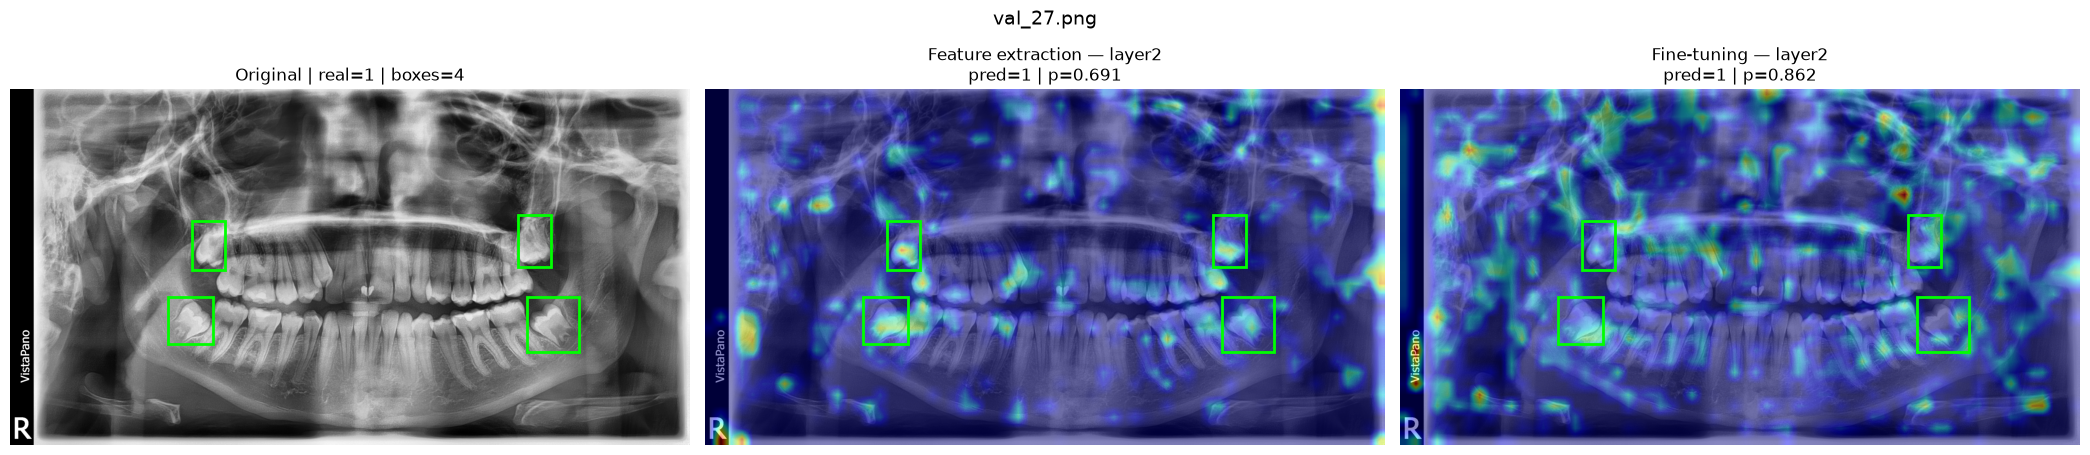


Fals negatiu: val_0.png


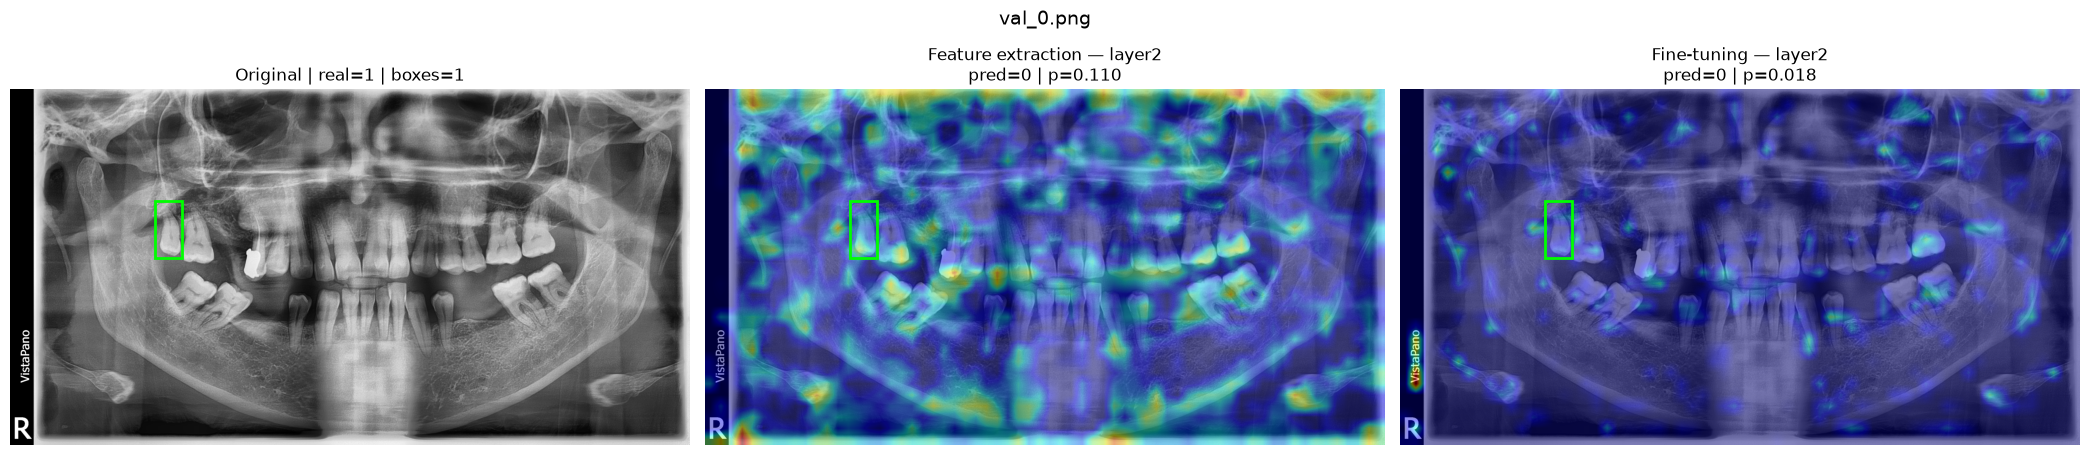


Fals positiu: val_4.png


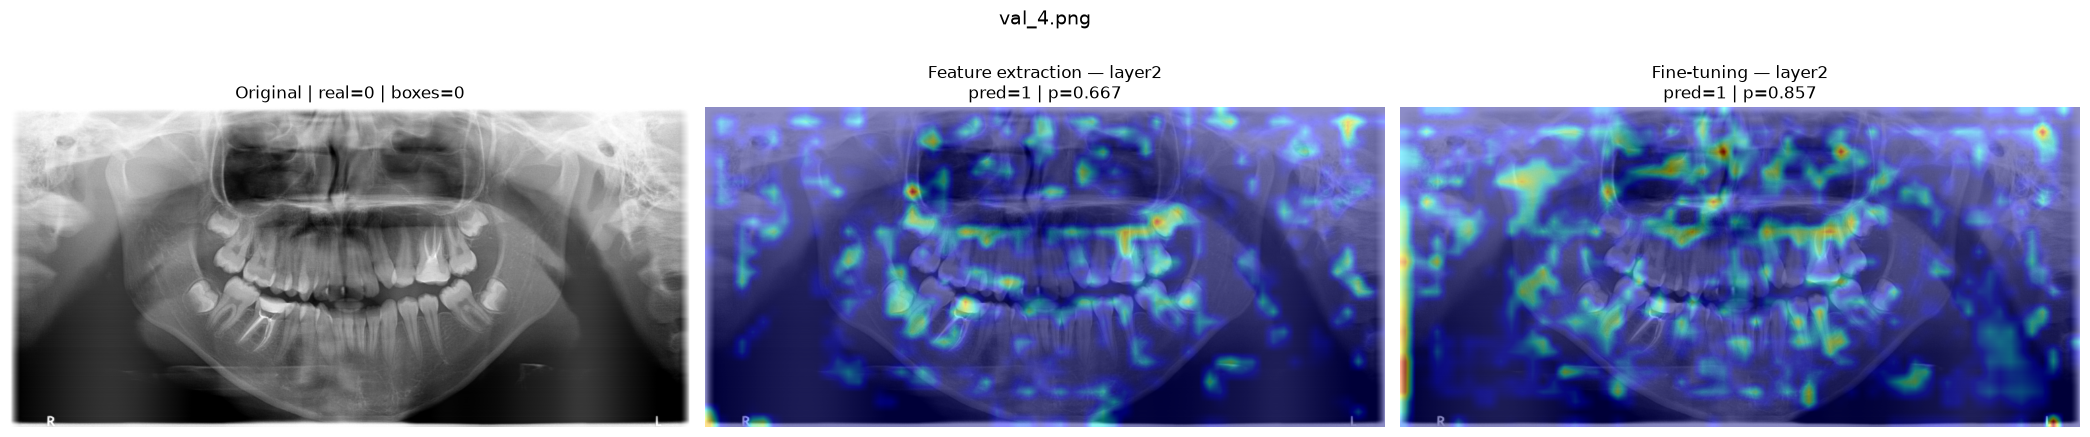


Vertader negatiu: val_40.png


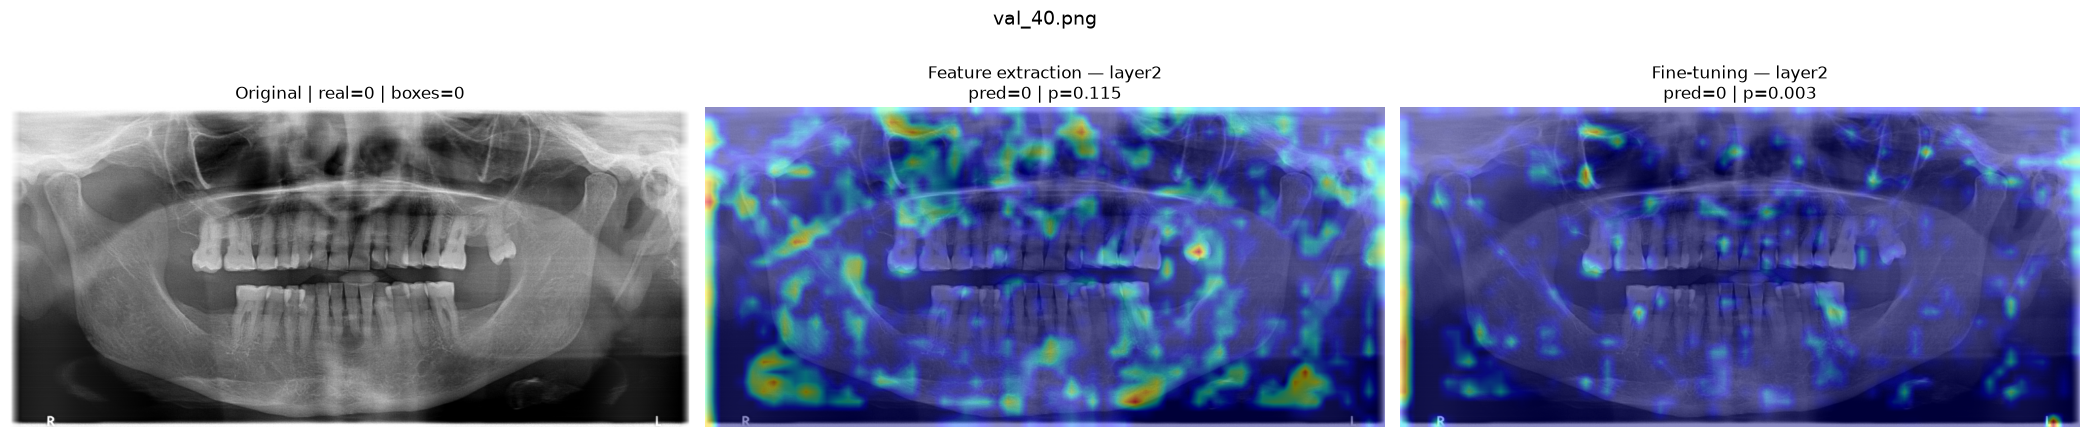

In [20]:
# Mateixes imatges que havíem triat per layer4.
for result_type, file_name in example_files.items():
    if file_name is not None:
        print(f"\n{result_type}: {file_name}")
        compare_layer2_gradcams(file_name)

In [ ]:
baseline_layer2_localization = evaluate_gradcam_localization(
    baseline_gradcam_layer2
)

finetuned_layer2_localization = evaluate_gradcam_localization(
    finetuned_gradcam_layer2
)

layer2_localization_comparison = pd.DataFrame([
    {
        "model": "Feature extraction — layer2",
        "pointing_accuracy": (
            baseline_layer2_localization["max_inside_box"].mean()
        ),
        "mean_energy_inside_box": (
            baseline_layer2_localization["energy_inside_box"].mean()
        ),
        "mean_concentration_ratio": (
            baseline_layer2_localization["concentration_ratio"].mean()
        )
    },
    {
        "model": "Fine-tuning — layer2",
        "pointing_accuracy": (
            finetuned_layer2_localization["max_inside_box"].mean()
        ),
        "mean_energy_inside_box": (
            finetuned_layer2_localization["energy_inside_box"].mean()
        ),
        "mean_concentration_ratio": (
            finetuned_layer2_localization["concentration_ratio"].mean()
        )
    }
])

display(layer2_localization_comparison)

,model,pointing_accuracy,mean_energy_inside_box,mean_concentration_ratio
0,Feature extraction — layer2,0.0625,0.039887,1.426271
1,Fine-tuning — layer2,0.0000,0.040052,1.414910


: 